In [4]:
!pip install -U pgmpy

Original Dataset:
   age  sex  chest  resting_blood_pressure  serum_cholestoral  \
0   70    1      4                     130                322   
1   67    0      3                     115                564   
2   57    1      2                     124                261   
3   64    1      4                     128                263   
4   74    0      2                     120                269   

   fasting_blood_sugar  resting_electrocardiographic_results  \
0                    0                                     2   
1                    0                                     2   
2                    0                                     0   
3                    0                                     0   
4                    0                                     2   

   maximum_heart_rate_achieved  exercise_induced_angina  oldpeak  slope  \
0                          109                        0      2.4      2   
1                          160                        0 

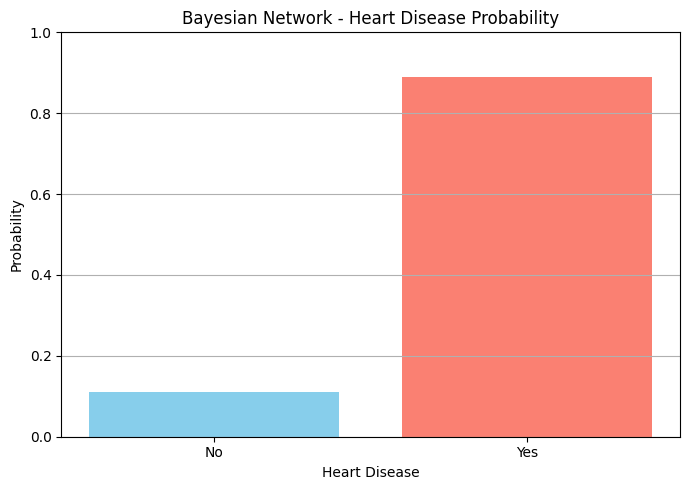

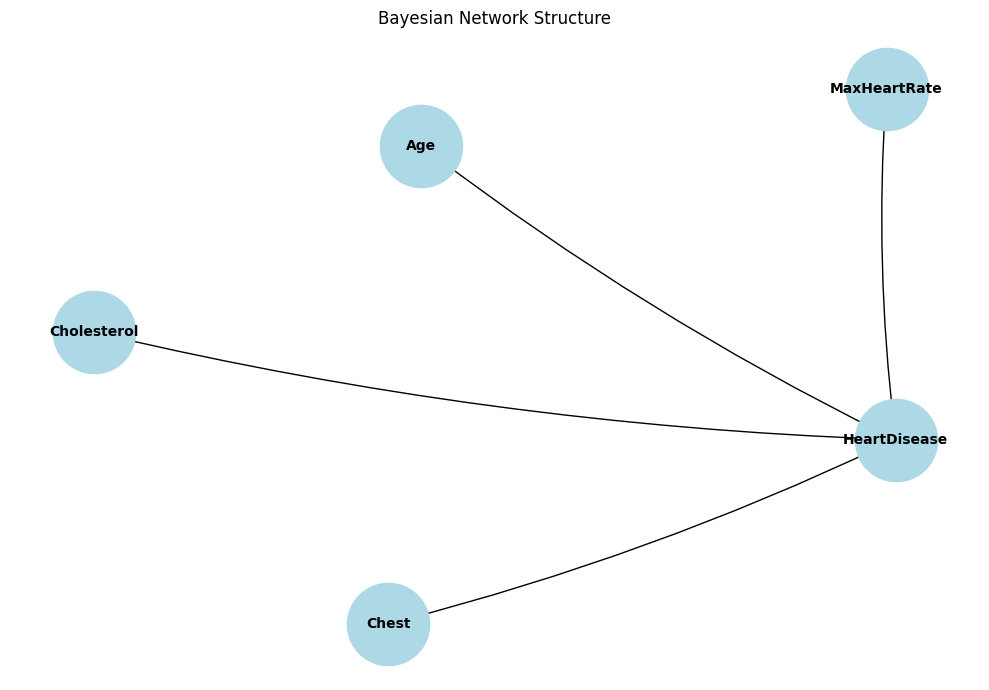


Probability Comparison by Age:
Young: 50.00%
Middle: 91.64%
Old: 89.05%


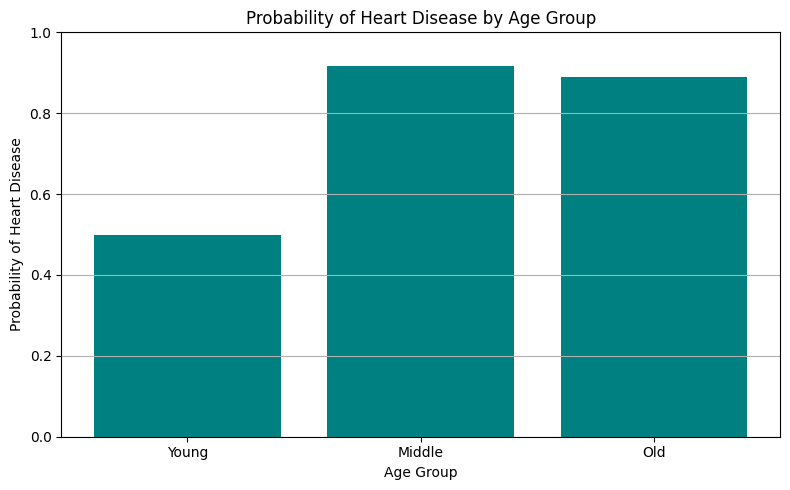

In [5]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split

from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator
from pgmpy.inference import VariableElimination

# 1. Load Dataset
data = fetch_openml(
    name="heart-statlog",
    version=1,
    as_frame=True
)

df = data.frame.copy()

print("Original Dataset:")
print(df.head())

print("\nDataset Shape:", df.shape)

# 2. Select Required Features
df = df[
    [
        'age',
        'chest',
        'serum_cholestoral',
        'maximum_heart_rate_achieved',
        'class'
    ]
].copy()

# 3. Rename Columns
df.columns = [
    'Age',
    'Chest',
    'Cholesterol',
    'MaxHeartRate',
    'HeartDisease'
]

# 4. Convert Numerical Features into Categories
df['Age'] = pd.cut(
    df['Age'],
    bins=[0, 40, 55, 100],
    labels=['Young', 'Middle', 'Old']
)

df['Cholesterol'] = pd.cut(
    df['Cholesterol'],
    bins=[0, 240, 1000],
    labels=['Normal', 'High']
)

df['MaxHeartRate'] = pd.cut(
    df['MaxHeartRate'],
    bins=[0, 150, 250],
    labels=['Low', 'High']
)

# 5. Convert Target into Yes/No
df['HeartDisease'] = (
    df['HeartDisease']
    .astype(str)
    .str.lower()
    .map({
        'present': 'Yes',
        'absent': 'No'
    })
)

# 6. Remove Missing Values
df = df.dropna().copy()

for col in df.columns:
    df[col] = df[col].astype(str)

print("\nProcessed Dataset:")
print(df.head())

print("\nProcessed Dataset Shape:", df.shape)

print("\nClass Distribution:")
print(df['HeartDisease'].value_counts())

# 7. Split Dataset
train_data, test_data = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df['HeartDisease']
)

print("\nTraining Data:", train_data.shape)
print("Testing Data:", test_data.shape)

# 8. Create Bayesian Network
model = DiscreteBayesianNetwork([
    ('Age', 'HeartDisease'),
    ('Chest', 'HeartDisease'),
    ('Cholesterol', 'HeartDisease'),
    ('MaxHeartRate', 'HeartDisease')
])

# 9. Train Bayesian Network using New API
estimator = DiscreteBayesianEstimator(
    prior_type="BDeu",
    equivalent_sample_size=10
)

model.fit(
    train_data,
    estimator=estimator
)

print("\nBayesian Network Structure:")
print(model.edges())

# 10. Check Model
print("\nModel Validity:", model.check_model())

# 11. Display Conditional Probability Distributions
print("\nConditional Probability Distributions:")

for cpd in model.get_cpds():
    print(cpd)
    print()

# 12. Perform Probability Inference
inference = VariableElimination(model)

result = inference.query(
    variables=['HeartDisease'],
    evidence={
        'Age': 'Old',
        'Chest': '4',
        'Cholesterol': 'High',
        'MaxHeartRate': 'Low'
    }
)

# 13. Display Estimated Probability
states = result.state_names['HeartDisease']
probabilities = result.values

print("\nEstimated Probability of Heart Disease:")

for state, probability in zip(states, probabilities):
    print(
        f"Probability of {state}: "
        f"{probability:.4f} ({probability * 100:.2f}%)"
    )

# 14. Visualize Event Probability
plt.figure(figsize=(7, 5))

plt.bar(
    states,
    probabilities,
    color=['skyblue', 'salmon']
)

plt.title("Bayesian Network - Heart Disease Probability")
plt.xlabel("Heart Disease")
plt.ylabel("Probability")
plt.ylim(0, 1)
plt.grid(axis='y')

plt.tight_layout()
plt.show()

# 15. Visualize Bayesian Network
plt.figure(figsize=(10, 7))

G = nx.DiGraph()
G.add_edges_from(model.edges())

pos = nx.spring_layout(G, seed=42)

nx.draw_networkx_nodes(
    G,
    pos,
    node_color='lightblue',
    node_size=3500
)

nx.draw_networkx_labels(
    G,
    pos,
    font_size=10,
    font_weight='bold'
)

nx.draw_networkx_edges(
    G,
    pos,
    arrows=True,
    arrowsize=25,
    edge_color='black',
    connectionstyle='arc3,rad=0.05'
)

plt.title("Bayesian Network Structure")
plt.axis('off')
plt.tight_layout()
plt.show()

# 16. Compare Probability for Different Age Groups
age_groups = ['Young', 'Middle', 'Old']
event_probabilities = []

for age in age_groups:

    prediction = inference.query(
        variables=['HeartDisease'],
        evidence={
            'Age': age,
            'Chest': '4',
            'Cholesterol': 'High',
            'MaxHeartRate': 'Low'
        }
    )

    yes_index = prediction.state_names[
        'HeartDisease'
    ].index('Yes')

    event_probabilities.append(
        prediction.values[yes_index]
    )

print("\nProbability Comparison by Age:")

for age, probability in zip(
    age_groups, event_probabilities
):
    print(
        f"{age}: {probability * 100:.2f}%"
    )

# 17. Visualize Age-wise Probability
plt.figure(figsize=(8, 5))

plt.bar(
    age_groups,
    event_probabilities,
    color='teal'
)

plt.title("Probability of Heart Disease by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Probability of Heart Disease")
plt.ylim(0, 1)
plt.grid(axis='y')

plt.tight_layout()
plt.show()
